# Semiconductor equity analysis

Assess common variation in NVDA, AMD, AVGO, TSM, MU, INTC, and ASML daily returns,
and how much remains after controlling for SPY.

## Data and sample

- **Source:** Yahoo Finance through `yfinance`; use the supplied `Adj Close`
  field with its split/dividend adjustments. The download uses
  `auto_adjust=False`, `actions=True`, `keepna=True`, and `repair=False`.
  Dividends are not added again. See the [download documentation](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html).
- **Listings:** the seven selected US-listed semiconductor shares and SPY,
  in USD. The Korean listings considered earlier are excluded.
- **Development sample:** 2010–2022. The download end `2023-01-01` is exclusive.
  Saved results contain 3,271 daily returns per ticker, from 5 January 2010 to
  30 December 2022.
- **Reserved final test:** 2023–2025, excluded from this notebook. The two
  development subperiods, 2010–2015 and 2016–2022, are exploratory comparisons.
- **Returns:** $r_{i,t}=P^{adj}_{i,t}/P^{adj}_{i,t-1}-1$, in decimals.
  Missing inputs are not filled; the first undefined return is dropped.

The data checks cover the returned index, missing prices, ordering, and duplicate
dates; they do not independently validate every exchange session or adjustment.
The notebook downloads fresh data on each run. The exact download timestamp and
raw snapshot for these saved results were not recorded, so subsequent revisions
may change the results.

In [50]:
%pip install yfinance
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [51]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import yfinance as yf

In [52]:
equity_groups = {
    "designers": ["NVDA", "AMD", "AVGO"],
    "manufacturers": ["TSM", "MU", "INTC"],  
    "equipment": ["ASML"],
}

equity_tickers = [
    ticker
    for tickers in equity_groups.values()
    for ticker in tickers
]

benchmark_ticker = "SPY"

In [53]:
tickers = equity_tickers + [benchmark_ticker]

prices = yf.download(
    tickers=tickers,
    start="2010-01-01",
    end="2023-01-01",
    interval="1d",
    auto_adjust=False,
    actions=True,
    keepna=True,
    repair=False,
)

[*********************100%***********************]  8 of 8 completed


In [54]:
prices.shape

(3272, 65)

In [55]:
prices.head()

Price      Adj Close                                                       \
Ticker           AMD       ASML      AVGO       INTC         MU      NVDA   
Date                                                                        
2010-01-04      9.70  32.228180  1.321281  13.519427  10.578572  0.422817   
2010-01-05      9.71  32.479240  1.331089  13.512953  10.890568  0.428992   
2010-01-06      9.57  32.776775  1.341597  13.467630  10.939319  0.431736   
2010-01-07      9.47  31.865545  1.333191  13.338135  10.568824  0.423275   
2010-01-08      9.43  31.103077  1.342998  13.487055  10.822317  0.424189   

Price                           Capital Gains Close  ... Stock Splits       \
Ticker            SPY       TSM           SPY   AMD  ...          SPY  TSM   
Date                                                 ...                     
2010-01-04  84.368980  7.199557           0.0  9.70  ...          0.0  0.0   
2010-01-05  84.592293  7.168471           0.0  9.71  ...          0.0  0.0   
2010-01-06  84.651878  7.143601           0.0  9.57  ...          0.0  0.0   
2010-01-07  85.009216  6.907348           0.0  9.47  ...          0.0  0.0   
2010-01-08  85.292114  6.901131           0.0  9.43  ...          0.0  0.0   

Price         Volume                                                   \
Ticker           AMD     ASML     AVGO      INTC        MU       NVDA   
Date                                                                    
2010-01-04  18748700  1390235  5387000  47800900  34412700  800204000   
2010-01-05  22145700  1094016  3011000  52357700  60659000  728648000   
2010-01-06  18643400  1051204  5331000  40037400  32060400  649168000   
2010-01-07  26806800  2057440  2718000  54041500  46461800  547792000   
2010-01-08  13752800  3027178  2899000  48234700  32433400  478168000   

Price                            
Ticker            SPY       TSM  
Date                             
2010-01-04  118944600   8096400  
2010-01-05  111579900  14375900  
2010-01-06  116074400  13608400  
2010-01-07  131091100  27346600  
2010-01-08  126402800  16895300  

[5 rows x 65 columns]

In [56]:
adjusted_close = prices["Adj Close"].copy()

data_check = pd.DataFrame({
    "first_date": adjusted_close.apply(
        lambda column: column.first_valid_index()
    ),
    "last_date": adjusted_close.apply(
        lambda column: column.last_valid_index()
    ),
    "missing_prices": adjusted_close.isna().sum(),
})

display(data_check)

print("Dates in order:", adjusted_close.index.is_monotonic_increasing)
print("Duplicate dates:", adjusted_close.index.has_duplicates)

,first_date,last_date,missing_prices
Ticker,,,
AMD,2010-01-04,2022-12-30,0
ASML,2010-01-04,2022-12-30,0
AVGO,2010-01-04,2022-12-30,0
INTC,2010-01-04,2022-12-30,0
MU,2010-01-04,2022-12-30,0
NVDA,2010-01-04,2022-12-30,0
SPY,2010-01-04,2022-12-30,0
TSM,2010-01-04,2022-12-30,0


Dates in order: True
Duplicate dates: False


In [57]:
returns = adjusted_close.pct_change(fill_method=None).iloc[1:]

In [58]:
returns.describe().T

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AMD,3271.0,0.001214,0.035865,-0.242291,-0.017180,0.000000,0.018542,0.522901
ASML,3271.0,0.001093,0.021806,-0.173492,-0.010148,0.000979,0.012685,0.145732
AVGO,3271.0,0.001380,0.022339,-0.199129,-0.010247,0.001490,0.012774,0.158337
INTC,3271.0,0.000368,0.018603,-0.180415,-0.008481,0.000468,0.009440,0.195213
MU,3271.0,0.000921,0.030024,-0.198185,-0.015171,0.000757,0.017504,0.234432
NVDA,3271.0,0.001474,0.028083,-0.187559,-0.012102,0.001447,0.015086,0.298067
SPY,3271.0,0.000509,0.011094,-0.109424,-0.003730,0.000653,0.005748,0.090603
TSM,3271.0,0.000865,0.018314,-0.140341,-0.009198,0.000764,0.010560,0.126522


In [59]:
returns.head()

Ticker,AMD,ASML,AVGO,INTC,MU,NVDA,SPY,TSM
Date,,,,,,,,
2010-01-05,0.001031,0.007790,0.007423,-0.000479,0.029493,0.014603,0.002647,-0.004318
2010-01-06,-0.014418,0.009161,0.007895,-0.003354,0.004476,0.006396,0.000704,-0.003469
2010-01-07,-0.010449,-0.027801,-0.006266,-0.009615,-0.033868,-0.019598,0.004221,-0.033072
2010-01-08,-0.004224,-0.023928,0.007357,0.011165,0.023985,0.002161,0.003328,-0.000900
2010-01-11,-0.030753,-0.021226,0.006260,0.005761,-0.018018,-0.014016,0.001396,-0.005406


## Daily return correlations

Calculate Pearson correlations between same-date daily returns, including SPY
as the broad US market proxy.

In [60]:
returns_correlation_matrix = returns.corr()
returns_correlation_matrix

Ticker,AMD,ASML,AVGO,INTC,MU,NVDA,SPY,TSM
Ticker,,,,,,,,
AMD,1.000000,0.441543,0.405989,0.416588,0.468813,0.550736,0.507432,0.433108
ASML,0.441543,1.000000,0.581688,0.571128,0.547588,0.583158,0.686336,0.614186
AVGO,0.405989,0.581688,1.000000,0.530823,0.524626,0.530774,0.640951,0.525535
INTC,0.416588,0.571128,0.530823,1.000000,0.555420,0.538908,0.678343,0.523603
MU,0.468813,0.547588,0.524626,0.555420,1.000000,0.556451,0.607576,0.527275
NVDA,0.550736,0.583158,0.530774,0.538908,0.556451,1.000000,0.632650,0.545652
SPY,0.507432,0.686336,0.640951,0.678343,0.607576,0.632650,1.000000,0.623229
TSM,0.433108,0.614186,0.525535,0.523603,0.527275,0.545652,0.623229,1.000000


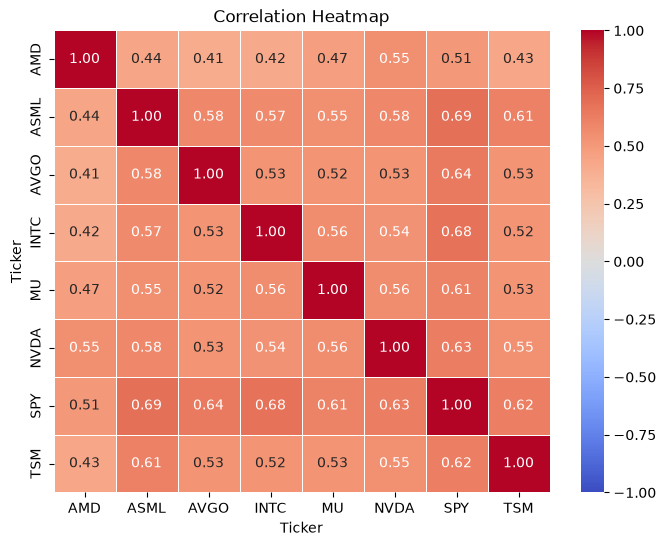

In [61]:
plt.figure(figsize=(8,6))
sns.heatmap(returns_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("Correlation Heatmap")
plt.show()

## Shared variation after controlling for SPY

Fit a separate OLS regression with an intercept for each semiconductor stock:

$$r_{i,t}=\alpha_i+\beta_i r_{\mathrm{SPY},t}+\varepsilon_{i,t}.$$

The fitted residual is the actual return minus the fitted return. Correlations
between these residuals measure shared variation beyond the fitted linear SPY
relationships. Refit the regressions within each subperiod. These are in-sample,
same-day relationships, not forecasts.

Subgroup entries average correlations between stock pairs, not correlations of
basket returns. Within-group summaries exclude self-correlations and count each
pair once; one-stock groups have no within-group estimate.

In [62]:
residuals = {}

for ticker in equity_tickers:
    regression_data = returns[[ticker, "SPY"]].dropna()
    y = regression_data[ticker]
    X = sm.add_constant(regression_data["SPY"])
    model = sm.OLS(y, X)
    result = model.fit()
    print(f"{ticker} - "f"Alpha: {result.params['const']:.6f}, "f"Beta: {result.params['SPY']:.4f}, "f"R-squared: {result.rsquared:.4f}")
    residuals[ticker] = result.resid


NVDA - Alpha: 0.000658, Beta: 1.6014, R-squared: 0.4002
AMD - Alpha: 0.000378, Beta: 1.6404, R-squared: 0.2575
AVGO - Alpha: 0.000723, Beta: 1.2906, R-squared: 0.4108
TSM - Alpha: 0.000341, Beta: 1.0288, R-squared: 0.3884
MU - Alpha: 0.000083, Beta: 1.6443, R-squared: 0.3691
INTC - Alpha: -0.000212, Beta: 1.1375, R-squared: 0.4601
ASML - Alpha: 0.000406, Beta: 1.3490, R-squared: 0.4711


In [63]:
residuals_df = pd.DataFrame(residuals)
residuals_df.head()

,NVDA,AMD,AVGO,TSM,MU,INTC,ASML
Date,,,,,,,
2010-01-05,0.009705,-0.003689,0.003284,-0.007382,0.025058,-0.003278,0.003814
2010-01-06,0.004610,-0.015952,0.006263,-0.004535,0.003235,-0.003943,0.007805
2010-01-07,-0.027016,-0.017752,-0.012437,-0.037756,-0.040892,-0.014205,-0.033901
2010-01-08,-0.003827,-0.010061,0.002339,-0.004665,0.018430,0.007591,-0.028823
2010-01-11,-0.016911,-0.033422,0.003735,-0.007184,-0.020397,0.004384,-0.023515


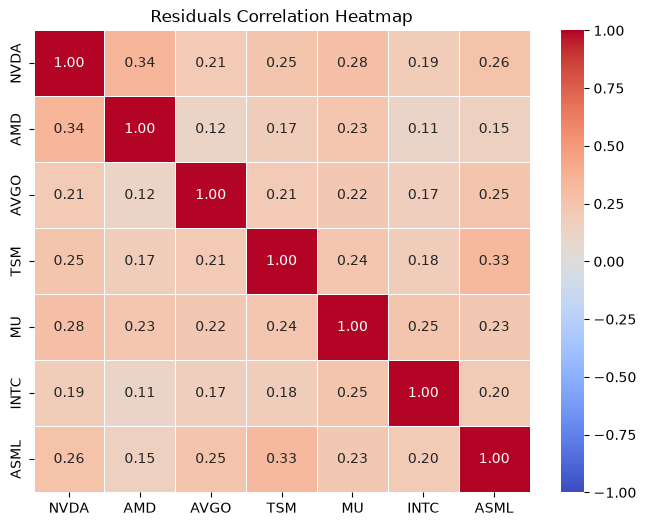

In [64]:
residuals_correlation_matrix = residuals_df.corr()

plt.figure(figsize=(8,6))
sns.heatmap(residuals_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("Residuals Correlation Heatmap")
plt.show()

Controlling for SPY substantially reduces pairwise correlations, but all remain
positive, ranging from approximately 0.11 to 0.34. This suggests shared variation
beyond the fitted SPY relationships. It does not establish that the variation is
semiconductor-specific or predictive. Next, compare business subgroups.

In [65]:
subgroups = {
    "design-led": ["NVDA", "AMD", "AVGO"],
    "foundry": ["TSM"],
    "integrated manufacturers": ["MU", "INTC"],
    "manufacturing equipment": ["ASML"],
}

In [66]:

def subgroup_correlations(correlation_matrix, groups):
    averages = pd.DataFrame(index=groups, columns=groups, dtype=float)

    for row_group, row_tickers in groups.items():
        for column_group, column_tickers in groups.items():
            block = correlation_matrix.loc[row_tickers, column_tickers].to_numpy()

            if row_group == column_group:
                
                pair_values = block[np.triu_indices(len(row_tickers), k=1)]
            else:
               
                pair_values = block.ravel()

            
            averages.loc[row_group, column_group] = (
                pair_values.mean() if pair_values.size else np.nan
            )

    return averages


subgroup_returns_correlation = subgroup_correlations(
    returns_correlation_matrix, subgroups
)
subgroup_residuals_correlation = subgroup_correlations(
    residuals_correlation_matrix, subgroups
)

print("Mean stock-pair correlations: original daily returns, 2010–2022")
display(subgroup_returns_correlation.round(3))

print("Mean stock-pair correlations: SPY-regression residuals, 2010–2022")
display(subgroup_residuals_correlation.round(3))

print("NaN means no within-group stock pair exists for that one-stock group.")


Mean stock-pair correlations: original daily returns, 2010–2022


,design-led,foundry,integrated manufacturers,manufacturing equipment
design-led,0.496,0.501,0.506,0.535
foundry,0.501,NaN,0.525,0.614
integrated manufacturers,0.506,0.525,0.555,0.559
manufacturing equipment,0.535,0.614,0.559,NaN


Mean stock-pair correlations: SPY-regression residuals, 2010–2022


,design-led,foundry,integrated manufacturers,manufacturing equipment
design-led,0.226,0.211,0.202,0.222
foundry,0.211,NaN,0.207,0.328
integrated manufacturers,0.202,0.207,0.246,0.212
manufacturing equipment,0.222,0.328,0.212,NaN


NaN means no within-group stock pair exists for that one-stock group.


## Comparison across development subperiods

Business groups do not form sharply separated clusters in the full sample.
Compare 2010–2015 with 2016–2022 to assess whether this pattern is stable across
time. These are exploratory calendar splits, not established economic regimes.
Use the same seven stocks and refit the SPY regressions within each period.

In [67]:
returns_2010_2015 = returns.loc['2010':'2015']
returns_2016_2022 = returns.loc['2016':'2022']

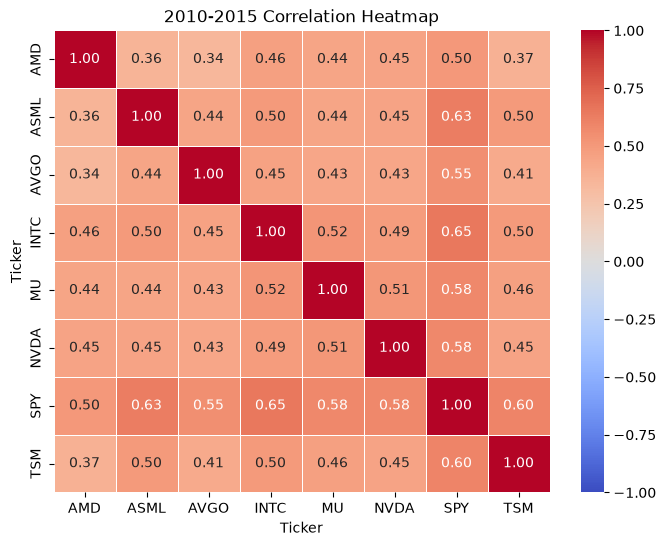

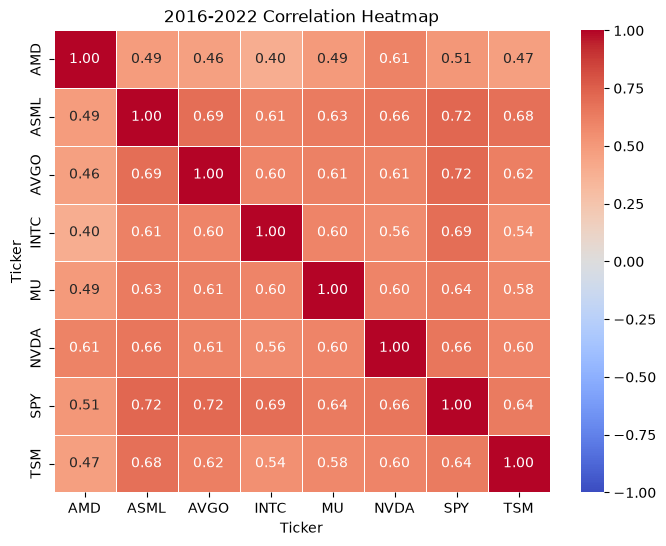

In [68]:
returns_2010_2015_correlation_matrix = returns_2010_2015.corr()
returns_2016_2022_correlation_matrix = returns_2016_2022.corr()

plt.figure(figsize=(8,6))
sns.heatmap(returns_2010_2015_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("2010-2015 Correlation Heatmap")
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(returns_2016_2022_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("2016-2022 Correlation Heatmap")
plt.show()

Average semiconductor stock-pair correlation is higher in 2016–2022 than in
2010–2015. This describes changes in same-day return co-movement; it does not
identify a cause such as AI or datacentre demand. Stocks rising over the same
period would not, by itself, establish correlated daily returns.

Next, compare residual correlations after fitting SPY regressions separately in
each period. The two residual heatmaps below show 2010–2015 first, followed by
2016–2022.

In [69]:
residuals_2010_2015 = {}
residuals_2016_2022 = {}

for ticker in equity_tickers:
    regression_data = returns_2010_2015[[ticker, "SPY"]].dropna()
    y = regression_data[ticker]
    X = sm.add_constant(regression_data["SPY"])
    model = sm.OLS(y, X)
    result = model.fit()
    print(f"{ticker} - "f"Alpha: {result.params['const']:.6f}, "f"Beta: {result.params['SPY']:.4f}, "f"R-squared: {result.rsquared:.4f}")
    residuals_2010_2015[ticker] = result.resid


for ticker in equity_tickers:
    regression_data = returns_2016_2022[[ticker, "SPY"]].dropna()
    y = regression_data[ticker]
    X = sm.add_constant(regression_data["SPY"])
    model = sm.OLS(y, X)
    result = model.fit()
    print(f"{ticker} - "f"Alpha: {result.params['const']:.6f}, "f"Beta: {result.params['SPY']:.4f}, "f"R-squared: {result.rsquared:.4f}")
    residuals_2016_2022[ticker] = result.resid
    


NVDA - Alpha: -0.000015, Beta: 1.3820, R-squared: 0.3361
AMD - Alpha: -0.001132, Beta: 1.6053, R-squared: 0.2524
AVGO - Alpha: 0.001012, Beta: 1.2627, R-squared: 0.3005
TSM - Alpha: 0.000208, Beta: 0.9795, R-squared: 0.3580
MU - Alpha: -0.000281, Beta: 1.7790, R-squared: 0.3347
INTC - Alpha: 0.000066, Beta: 0.9783, R-squared: 0.4280
ASML - Alpha: 0.000144, Beta: 1.2538, R-squared: 0.3963
NVDA - Alpha: 0.001268, Beta: 1.7308, R-squared: 0.4387
AMD - Alpha: 0.001677, Beta: 1.6613, R-squared: 0.2612
AVGO - Alpha: 0.000479, Beta: 1.3071, R-squared: 0.5152
TSM - Alpha: 0.000463, Beta: 1.0580, R-squared: 0.4067
MU - Alpha: 0.000375, Beta: 1.5649, R-squared: 0.4036
INTC - Alpha: -0.000426, Beta: 1.2313, R-squared: 0.4812
ASML - Alpha: 0.000644, Beta: 1.4051, R-squared: 0.5194


In [70]:
residuals_2010_2015_df = pd.DataFrame(residuals_2010_2015)
residuals_2016_2022_df = pd.DataFrame(residuals_2016_2022)

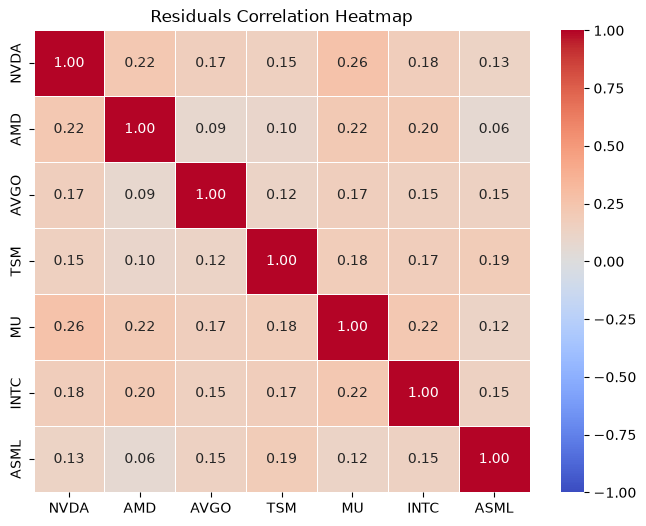

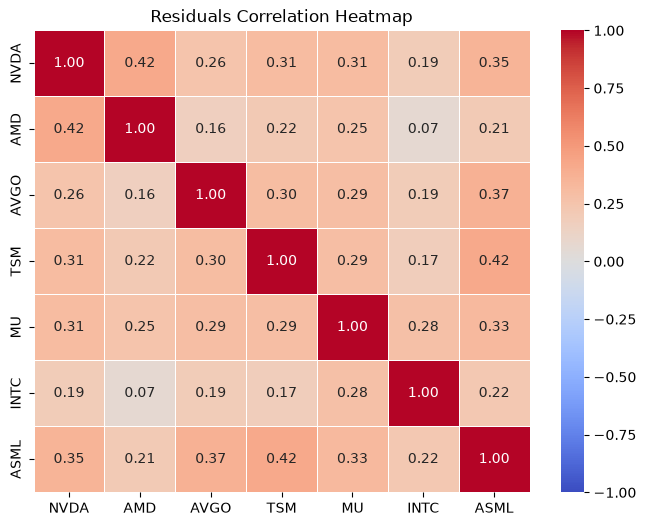

In [71]:
residuals_2010_2015_correlation_matrix = residuals_2010_2015_df.corr()
residuals_2016_2022_correlation_matrix = residuals_2016_2022_df.corr()

plt.figure(figsize=(8,6))
sns.heatmap(residuals_2010_2015_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("Residuals Correlation Heatmap")
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(residuals_2016_2022_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("Residuals Correlation Heatmap")
plt.show()

Shared return variation beyond SPY is present in both periods, but its strength and distribution across stock pairs change. Several relationships are stronger in 2016–2022, particularly NVDA–AMD and TSM–ASML. These results do not establish the economic causes of that change.

In [72]:

def mean_stock_pair_correlation(correlation_matrix):
    stock_matrix = correlation_matrix.loc[
        equity_tickers, equity_tickers
    ].to_numpy()

    pair_values = stock_matrix[
        np.triu_indices(len(equity_tickers), k=1)
    ]
    return pair_values.mean()


period_matrices = {
    "2010–2015": (
        returns_2010_2015_correlation_matrix,
        residuals_2010_2015_correlation_matrix,
    ),
    "2016–2022": (
        returns_2016_2022_correlation_matrix,
        residuals_2016_2022_correlation_matrix,
    ),
}


period_comparison = pd.DataFrame({
    period: {
        "Mean original correlation":
            mean_stock_pair_correlation(original_matrix),
        "Mean residual correlation":
            mean_stock_pair_correlation(residual_matrix),
    }
    for period, (original_matrix, residual_matrix)
    in period_matrices.items()
}).T

period_comparison.index.name = "Period"
display(period_comparison.round(3))


period_subgroup_residual_correlations = {}

for period, (_, residual_matrix) in period_matrices.items():
    group_table = subgroup_correlations(residual_matrix, subgroups)
    period_subgroup_residual_correlations[period] = group_table

    print(f"{period}: residual correlations by subgroup")
    display(group_table.round(3))

,Mean original correlation,Mean residual correlation
Period,,
2010–2015,0.447,0.162
2016–2022,0.577,0.267


2010–2015: residual correlations by subgroup


,design-led,foundry,integrated manufacturers,manufacturing equipment
design-led,0.159,0.123,0.197,0.113
foundry,0.123,NaN,0.176,0.195
integrated manufacturers,0.197,0.176,0.223,0.133
manufacturing equipment,0.113,0.195,0.133,NaN


2016–2022: residual correlations by subgroup


,design-led,foundry,integrated manufacturers,manufacturing equipment
design-led,0.277,0.275,0.218,0.308
foundry,0.275,NaN,0.234,0.419
integrated manufacturers,0.218,0.234,0.280,0.276
manufacturing equipment,0.308,0.419,0.276,NaN


## Conclusion

The seven semiconductor stocks show positive co-movement beyond their fitted relationships with SPY in both periods. Average pairwise correlation falls from 0.447 to 0.162 after controlling for SPY in 2010–2015, and from 0.577 to 0.267 in 2016–2022. Shared variation therefore remains after market adjustment and is stronger in the later sample. Business subgroups do not form clearly separated clusters, with some strong relationships crossing supply-chain roles, particularly TSM–ASML. These descriptive results support further investigation of shared influences, but do not establish their economic causes, statistical significance, or usefulness for predicting future returns.